# ETF allocation controls: a completed, full-support development study

Does a fixed trend gate or volatility scaler change the return/risk tradeoff of eight strategic ETF sleeves? This analysis uses the completed cloud ledgers for **every one of 1,975 XNYS sessions, March 1, 2007–December 31, 2014**, for all four prespecified controls. It does not fit a model or rerun a strategy. **These are development results, not a final holdout evaluation or a reliable-edge claim.**

The public CSV contains only derived portfolio accounting results. The original OHLC and provider responses remain private. Run `uv run --group research python scripts/build_etf_notebook.py --report reports/etf_controls_v3 --output notebooks/04_etf_controls.ipynb` to reproduce this notebook from the public results.

## Contract and source verification

The four controls use SPY, EFA, EEM, TLT, LQD, GLD, DBC and VNQ. Each starts with $100,000 at the February 28, 2007 decision close, trades at the following scheduled open, pays 10 bp on each traded side, and earns zero on cash. There are no shorts or leverage. The exporter authenticated all fourteen scientific study outputs before reading any ledger. Here we independently authenticate all portable report artifacts before calculation.

The Yahoo release is a separate whole-source vintage. Every adjusted OHLC proxy is observed provider OHLC × same-row published AdjClose/Close. It is not the original archive and has no archive-SHA alias. Adjusted opens are research proxies; actual auction fills, dividend cash settlement and historical publication/vintage availability are unverified.

In [1]:
from pathlib import Path
import hashlib, json, math
import numpy as np
import pandas as pd
from IPython.display import display, Image

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').exists())
report = root / 'reports/etf_controls_v3'
sha = lambda p: hashlib.sha256(p.read_bytes()).hexdigest()
manifest = json.loads((report / 'export_manifest.json').read_text())
assert (report / 'COMPLETE').read_text().strip() == sha(report / 'export_manifest.json')
assert manifest['complete'] and manifest['portfolio_rows'] == 7900
for name, expected in manifest['outputs_sha256'].items():
    assert sha(report / name) == expected, name
provenance = json.loads((report / 'provenance.json').read_text())
assert provenance['source_identity']['archive_sha256'] is None
assert not provenance['holdout_evaluated'] and not provenance['strategy_rerun']
print('Verified portable report artifact hashes; provenance records exporter verification of 14 cloud outputs. Four controls × 1,975 sessions.')
display(pd.Series({k: provenance[k] for k in ['study_manifest_sha256','price_basis','sessions_per_policy','initial_cash','fee_bps_per_traded_side']}))

Verified portable report artifact hashes; provenance records exporter verification of 14 cloud outputs. Four controls × 1,975 sessions.


study_manifest_sha256      109976808a1196c62111b14877271b94049ce6df7964e2...
price_basis                provider_adjusted_close_ratio_price_index_rese...
sessions_per_policy                                                     1975
initial_cash                                                        100000.0
fee_bps_per_traded_side                                                   10
dtype: object

## Independent accounting and metric reconstruction

For daily net return, $r_t=V_t/V_{t-1}-1$, with $V_0=100000$. Annual return uses $(V_T/V_0)^{252/T}-1$; sample volatility is $s(r)\sqrt{252}$ with ddof=1; Sharpe is $\bar r/s(r)\sqrt{252}$ against the declared zero cash rate. Drawdown uses the largest earlier close NAV **including initial capital**. Fees and full buy-plus-sell turnover are summed over every measured day, including initial entry.

The following calculation uses the CSV directly and checks the cloud-derived metric export. It also verifies cash plus sleeve values equals NAV, 10 bp × traded notional equals fees, and NAV changes equal daily money P&L.

In [2]:
daily = pd.read_csv(report / 'portfolio_daily.csv', parse_dates=['session'], float_precision='round_trip')
saved = pd.read_csv(report / 'metrics.csv', index_col='policy', float_precision='round_trip')
policies = manifest['policies']
rows = []
for policy in policies:
    f = daily.loc[daily.policy == policy].copy()
    assert len(f) == 1975 and f.session.is_unique and f.session.is_monotonic_increasing
    nav = f.close_nav.to_numpy()
    previous = np.r_[100000., nav[:-1]]
    r = nav / previous - 1
    values = f.filter(regex='^value_').sum(axis=1).to_numpy()
    np.testing.assert_allclose(nav, values + f.cash, rtol=0, atol=1e-7)
    np.testing.assert_allclose(f.fee, .001 * f.traded_notional, rtol=0, atol=1e-8)
    np.testing.assert_allclose(f.money_pnl, nav - previous, rtol=0, atol=1e-7)
    sigma = r.std(ddof=1)
    row = dict(policy=policy, net_return=nav[-1]/100000.-1,
        annual_return_252_session_convention=(nav[-1]/100000.)**(252/len(nav))-1,
        annual_volatility_sample_ddof1=sigma*np.sqrt(252),
        annual_sharpe_zero_cash_reference=r.mean()/sigma*np.sqrt(252),
        maximum_close_nav_drawdown=(nav/np.maximum.accumulate(np.maximum(nav,100000.))-1).min(),
        mean_close_risky_weight=np.mean(values/nav), total_fee_money=math.fsum(f.fee),
        total_full_buy_plus_sell_turnover=math.fsum(f.full_turnover))
    for metric, value in row.items():
        if metric != 'policy':
            assert np.isclose(value, saved.loc[policy,metric], rtol=1e-10, atol=1e-10), metric
    rows.append(row)
metrics = pd.DataFrame(rows).set_index('policy')
formatted = metrics.T.astype(object).copy()
percent_rows = [name for name in metrics if name not in ['annual_sharpe_zero_cash_reference', 'total_fee_money', 'total_full_buy_plus_sell_turnover']]
for name in formatted.index:
    template = '{:.2%}' if name in percent_rows else ('${:,.2f}' if name == 'total_fee_money' else '{:.3f}')
    formatted.loc[name] = metrics[name].map(lambda value: template.format(value))
formatted.columns = ['Strategic equal', 'Trend', 'Volatility', 'Trend + volatility']
display(formatted)


,Strategic equal,Trend,Volatility,Trend + volatility
net_return,52.02%,52.81%,36.37%,49.23%
annual_return_252_session_convention,5.49%,5.56%,4.04%,5.24%
annual_volatility_sample_ddof1,15.62%,8.65%,9.87%,7.76%
annual_sharpe_zero_cash_reference,0.420,0.669,0.450,0.697
maximum_close_nav_drawdown,-39.27%,-11.22%,-22.88%,-11.22%
mean_close_risky_weight,100.00%,71.36%,80.95%,66.52%
total_fee_money,$463.21,"$1,355.95",$788.16,"$1,526.01"
total_full_buy_plus_sell_turnover,4.096,10.879,7.083,12.609


## The four controls

| Control | Rule held fixed throughout development |
|---|---|
| Strategic equal | Monthly rebalance to 12.5% in each of eight sleeves |
| Trend | Keep a sleeve's 12.5% budget only when its trailing 252-return price-index return is positive; inactive budgets stay in cash |
| Volatility | Scale equal-sleeve budgets using 63 past daily returns and sample covariance to 10% annual risk; scaling capped at 1 |
| Combined | Apply the same trend gate, then the same volatility scaler |

A 10% forecast target is not a guarantee about subsequently realized risk. No cost-free counterfactual is constructed. Terminal holdings are marked at the observed close; the final target remains pending, without an invented January 2015 fill or liquidation charge.

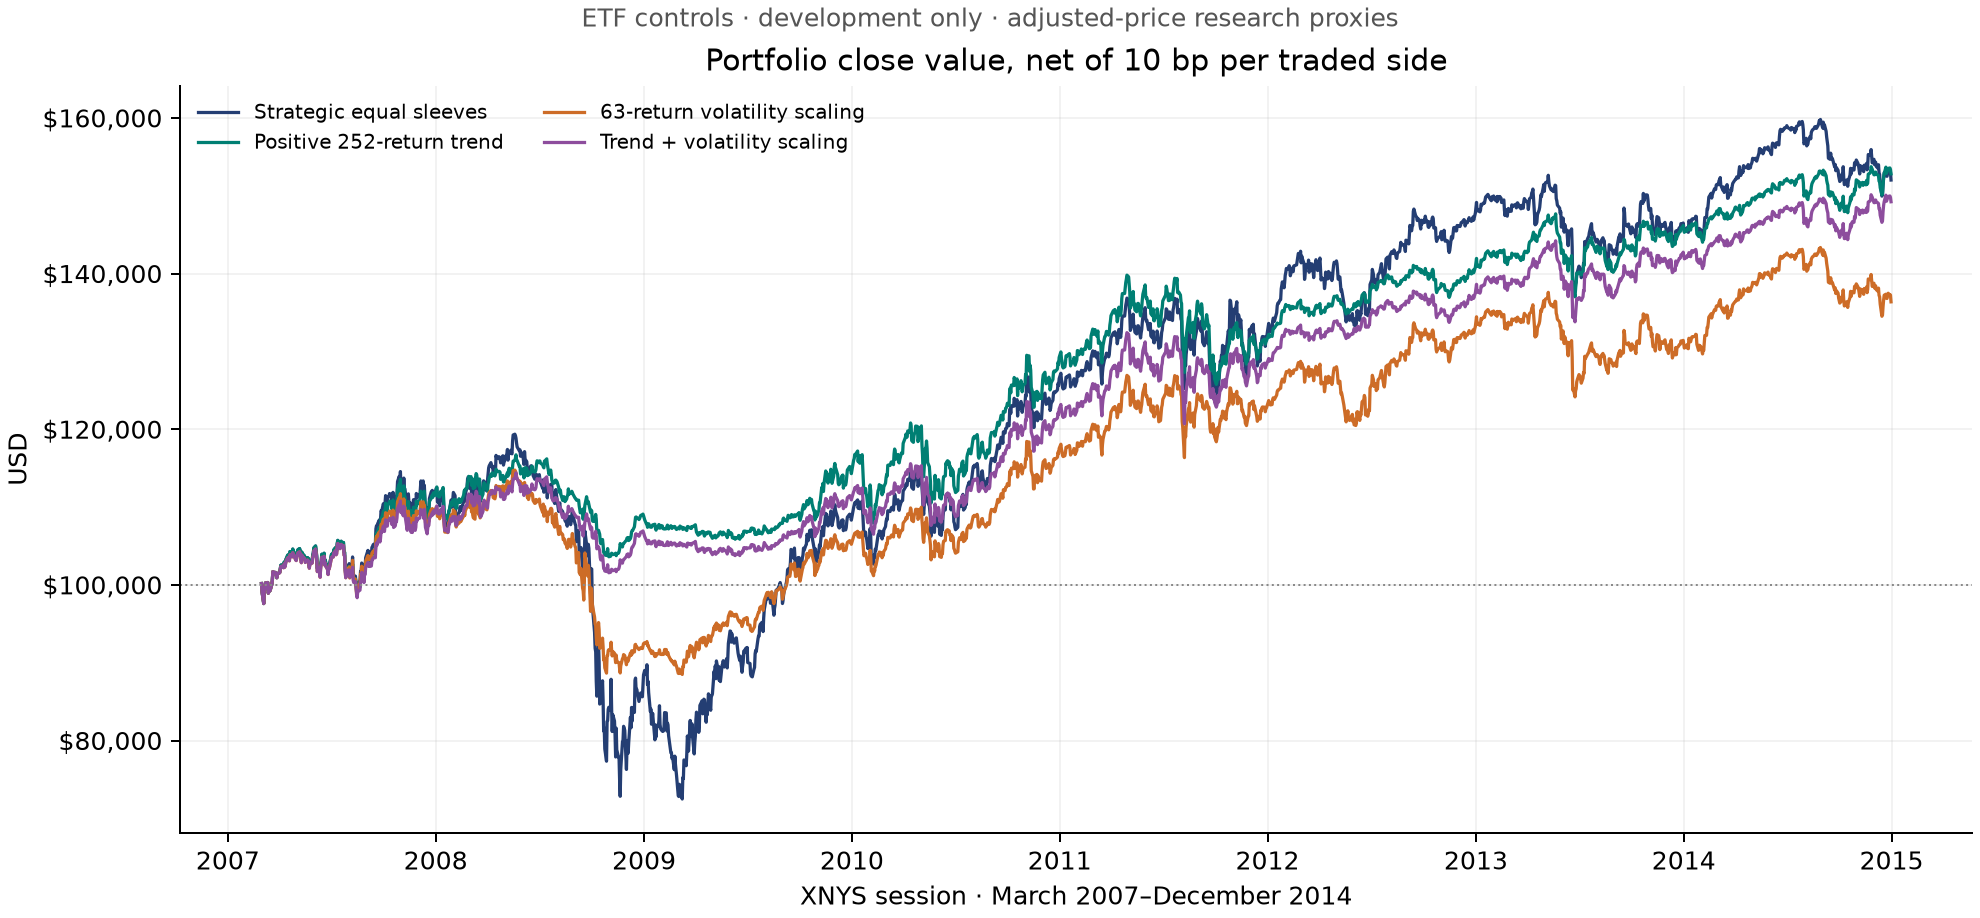

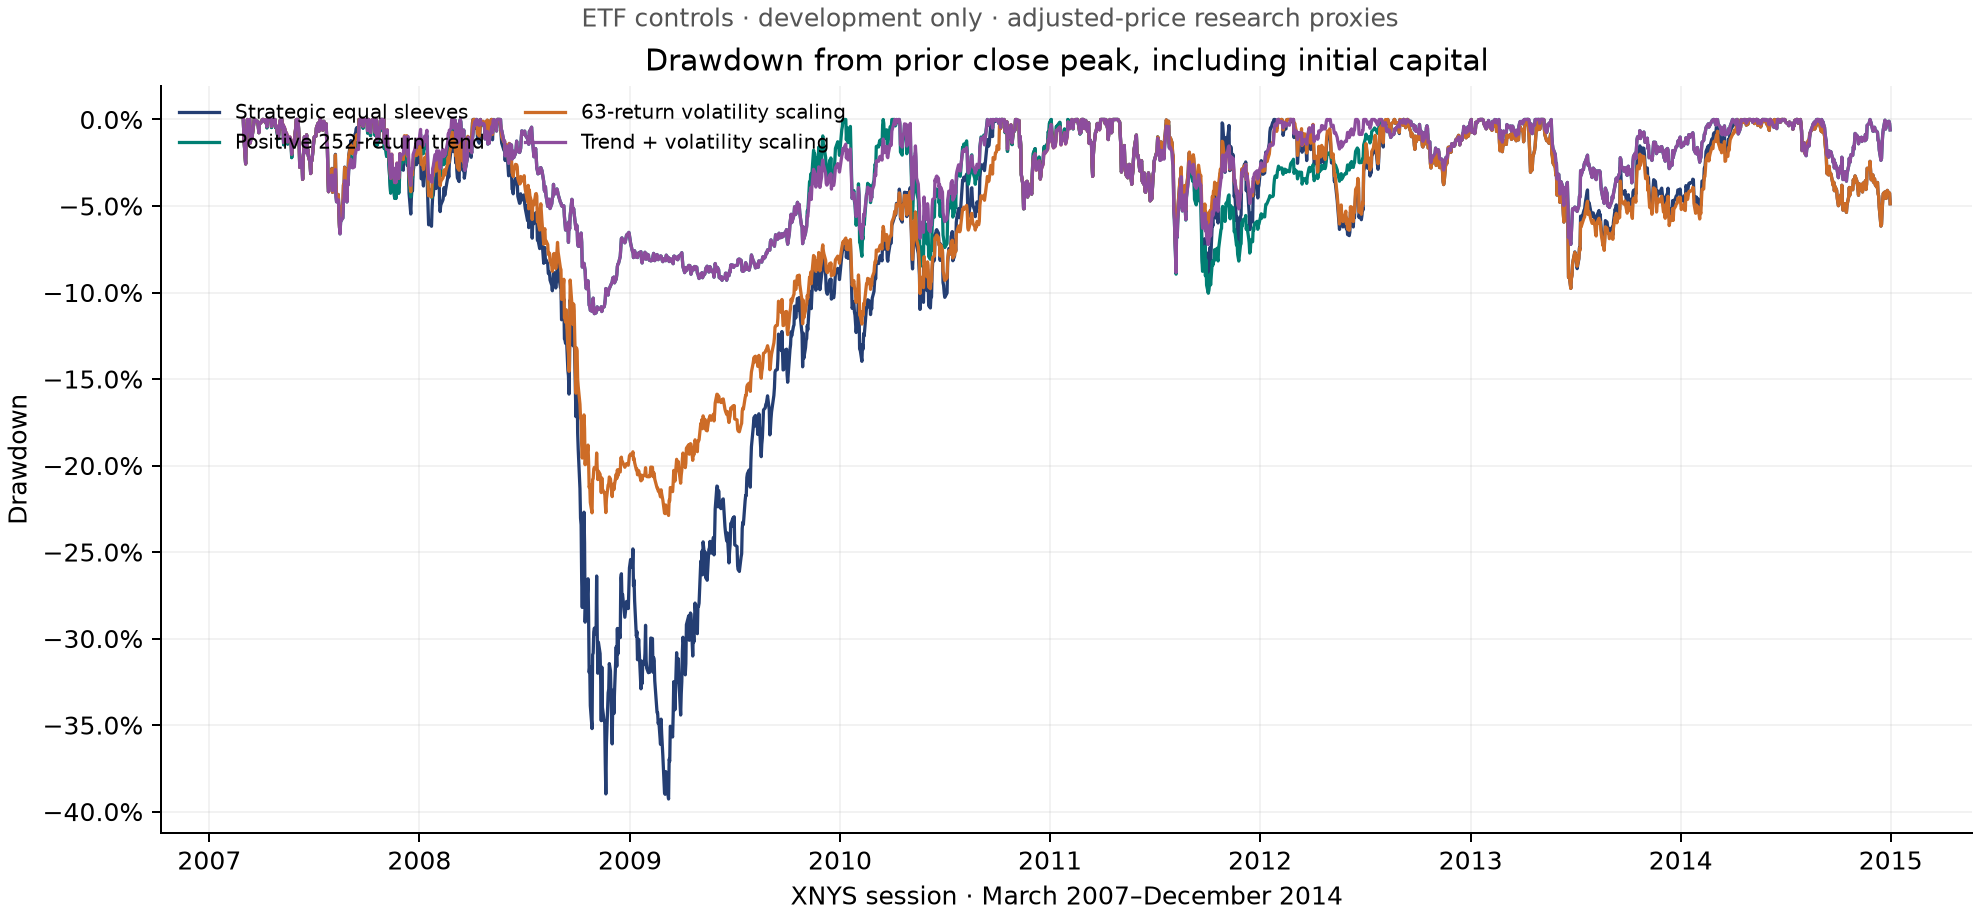

In [3]:
display(Image(filename=str(report / 'equity.png')))
display(Image(filename=str(report / 'drawdown.png')))

## Risk, cash allocation and trading costs

The trend gate materially lowers invested exposure during this observed history. Cash budgets are retained rather than renormalized into the remaining sleeves. Volatility scaling further changes exposure and trading activity. Rolling realized volatility needs 63 observations: the first 62 values are unavailable, not filled. The 2007 row below is a partial calendar year starting March 1.

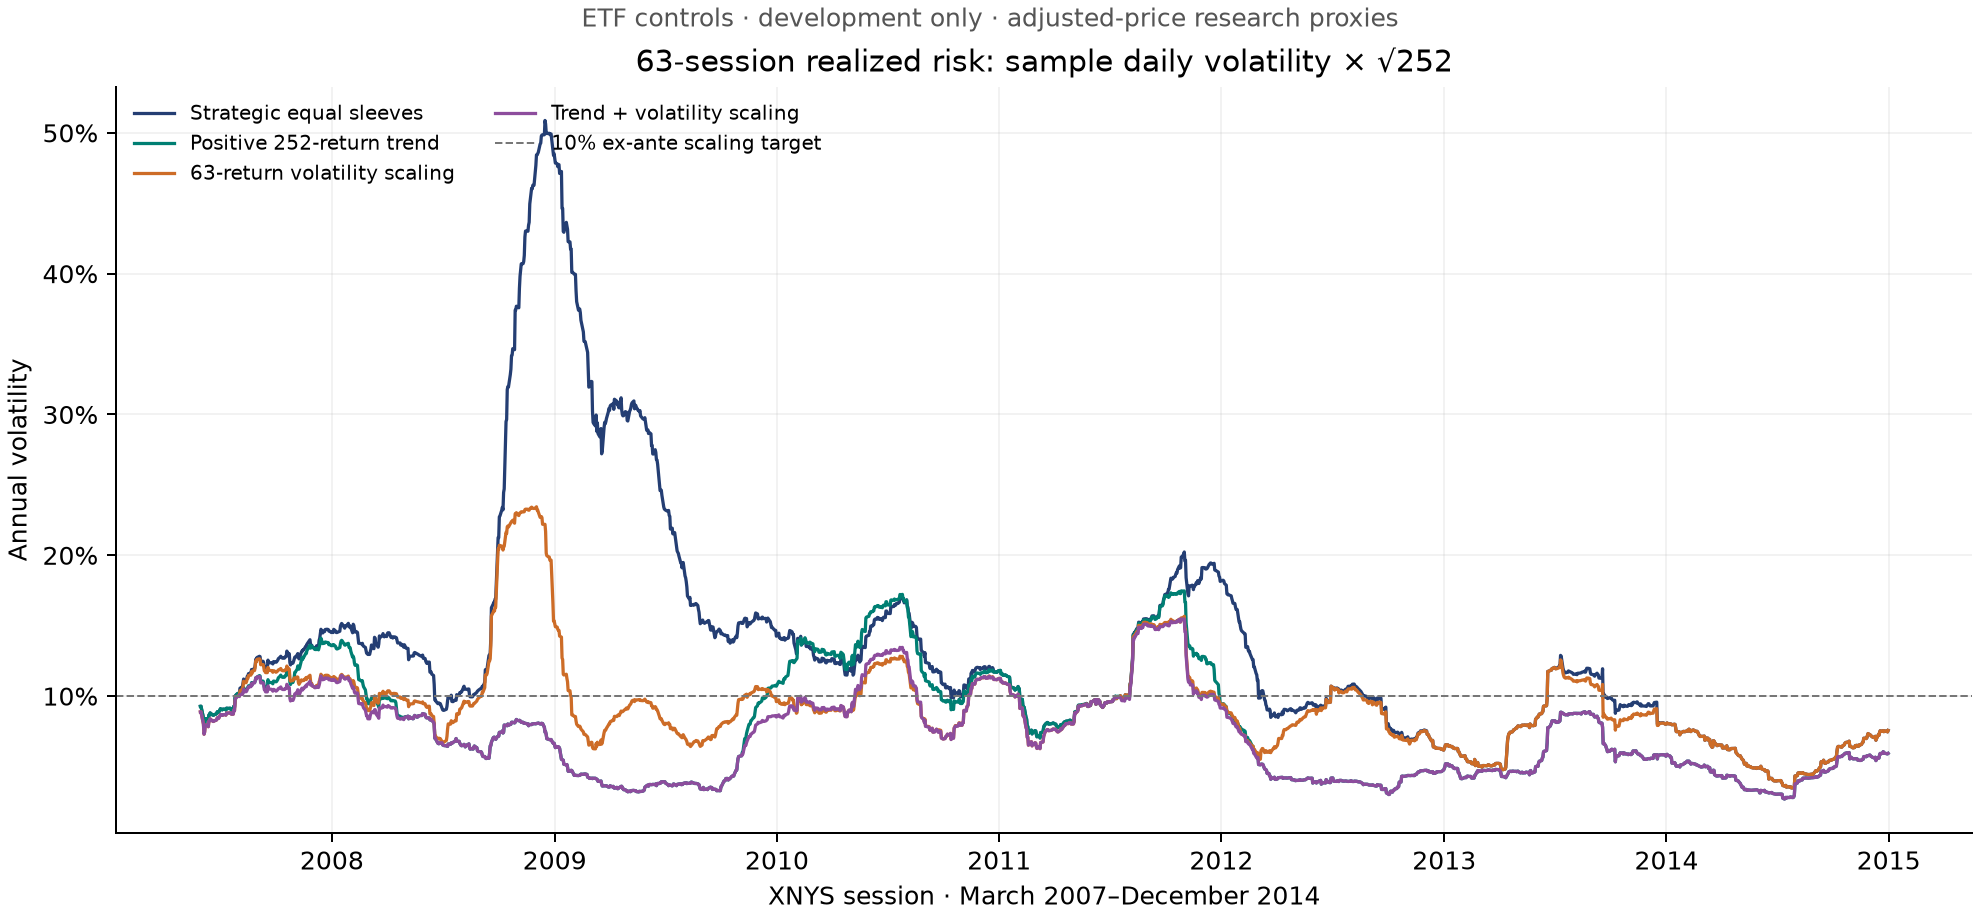

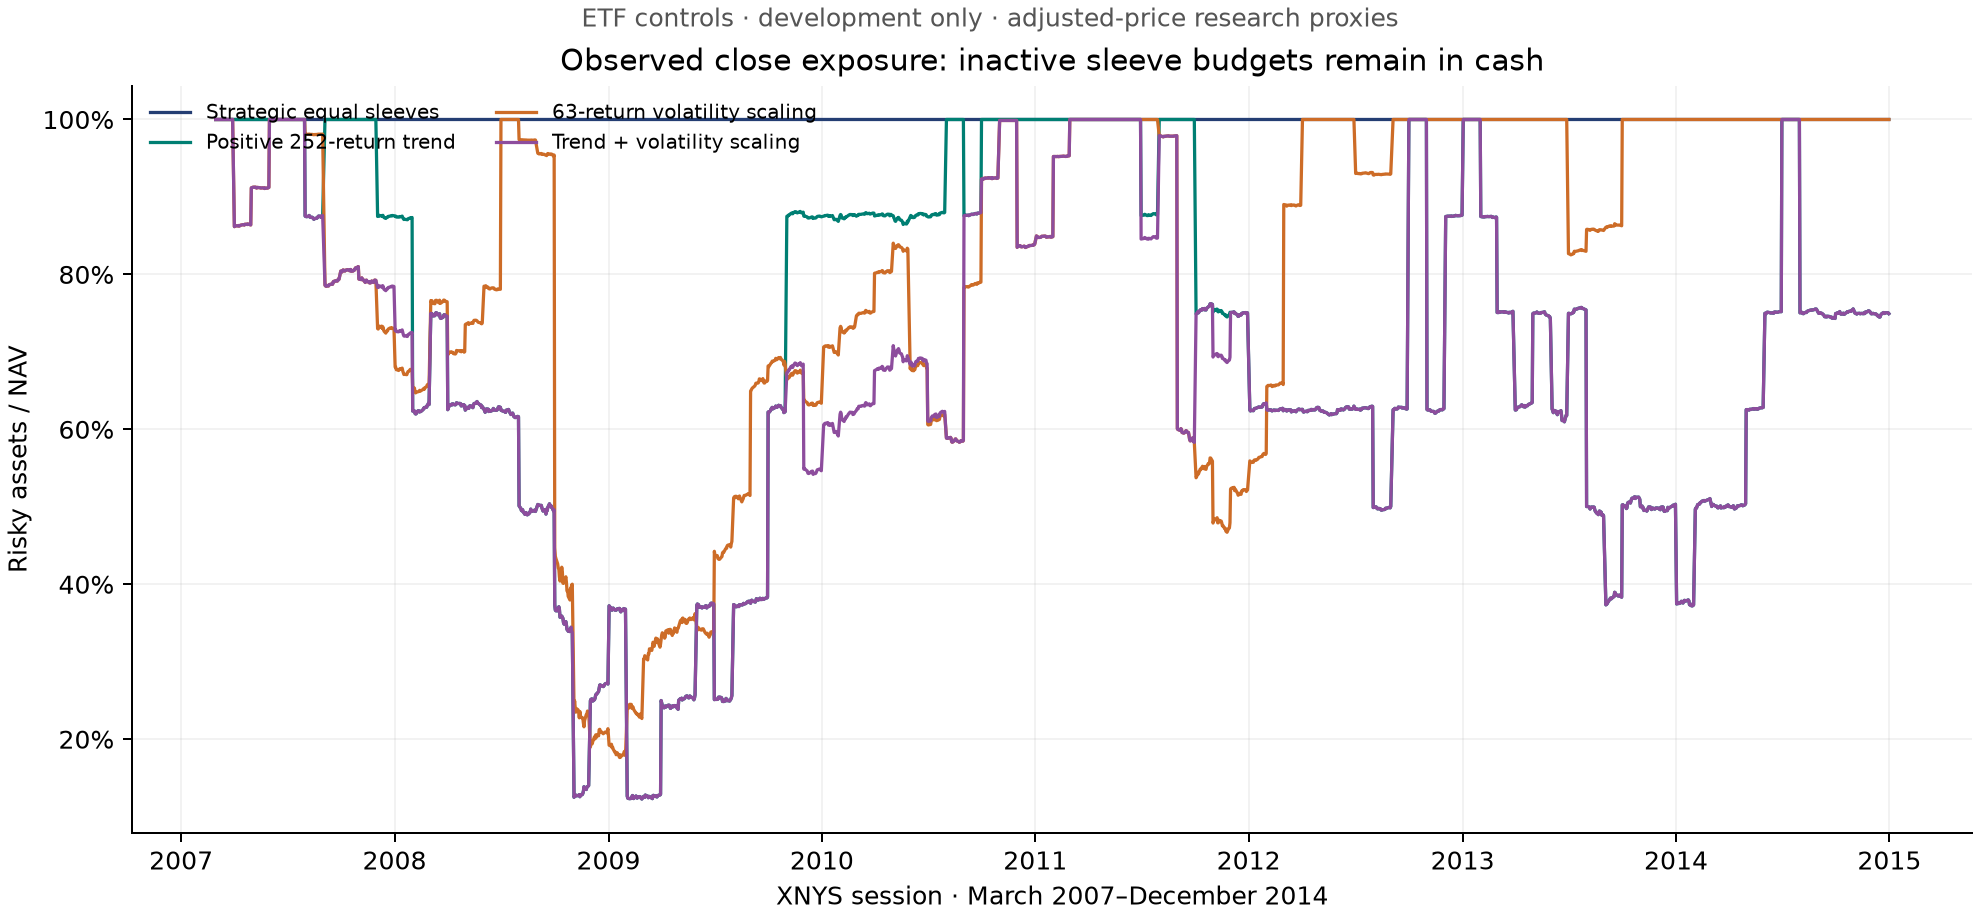

policy,strategic_equal,trend_252,volatility_63,trend_252_volatility_63
year,,,,
2007,11.71%,11.51%,9.49%,9.23%
2008,-20.85%,-2.36%,-15.57%,-2.29%
2009,22.49%,4.96%,13.81%,3.93%
2010,16.79%,13.07%,11.71%,10.55%
2011,4.06%,1.65%,4.42%,4.62%
2012,12.26%,7.21%,8.55%,7.21%
2013,-0.87%,3.80%,-1.35%,3.80%
2014,3.77%,4.54%,3.77%,4.54%


,monthly_decisions,terminal_pending_target,last_intended_execution_at
strategic_equal,95,True,2015-01-02T14:30:00+00:00
trend_252,95,True,2015-01-02T14:30:00+00:00
trend_252_volatility_63,95,True,2015-01-02T14:30:00+00:00
volatility_63,95,True,2015-01-02T14:30:00+00:00


In [4]:
display(Image(filename=str(report / 'rolling_risk.png')))
display(Image(filename=str(report / 'exposure.png')))
annual = daily.assign(year=daily.session.dt.year).groupby(['year','policy']).daily_net_return.agg(lambda r: np.prod(1+r)-1).unstack('policy')[policies]
display(annual.map(lambda value: f'{value:.2%}'))
support = pd.DataFrame(provenance['monthly_target_support']).T
display(support[['monthly_decisions','terminal_pending_target','last_intended_execution_at']])

## Paired uncertainty: descriptive, after seeing development results

All three controls are compared with strategic equal sleeves using shared observed-session indices, circular contiguous blocks of 21/63/126 sessions, 2,000 draws per block length and seed 20261017. This resamples the actual net-return observations; it does not invent prices, refit a model, or replay execution costs. The stored uncertainty report's exact return-input hashes were matched to these ledgers by the exporter.

These intervals were added **after** the control scores were observed. They are not 2014-preregistered, not adjusted for strategy selection, and assume representative history and adequate dependence capture by the chosen block lengths. Every 95% interval crosses zero.

observed_Sharpe_difference  lower_95  \
policy                  block_sessions                                         
trend_252               21                                  0.2484   -0.2554   
                        63                                  0.2484   -0.3003   
                        126                                 0.2484   -0.2933   
trend_252_volatility_63 21                                  0.2769   -0.2325   
                        63                                  0.2769   -0.2536   
                        126                                 0.2769   -0.2443   
volatility_63           21                                  0.0302   -0.2536   
                        63                                  0.0302   -0.2244   
                        126                                 0.0302   -0.2057   

                                        upper_95  
policy                  block_sessions            
trend_252               21                0.7452  
                        63                0.6959  
                        126               0.7174  
trend_252_volatility_63 21                0.7594  
                        63                0.6981  
                        126               0.6993  
volatility_63           21                0.2942  
                        63                0.2393  
                        126               0.2146

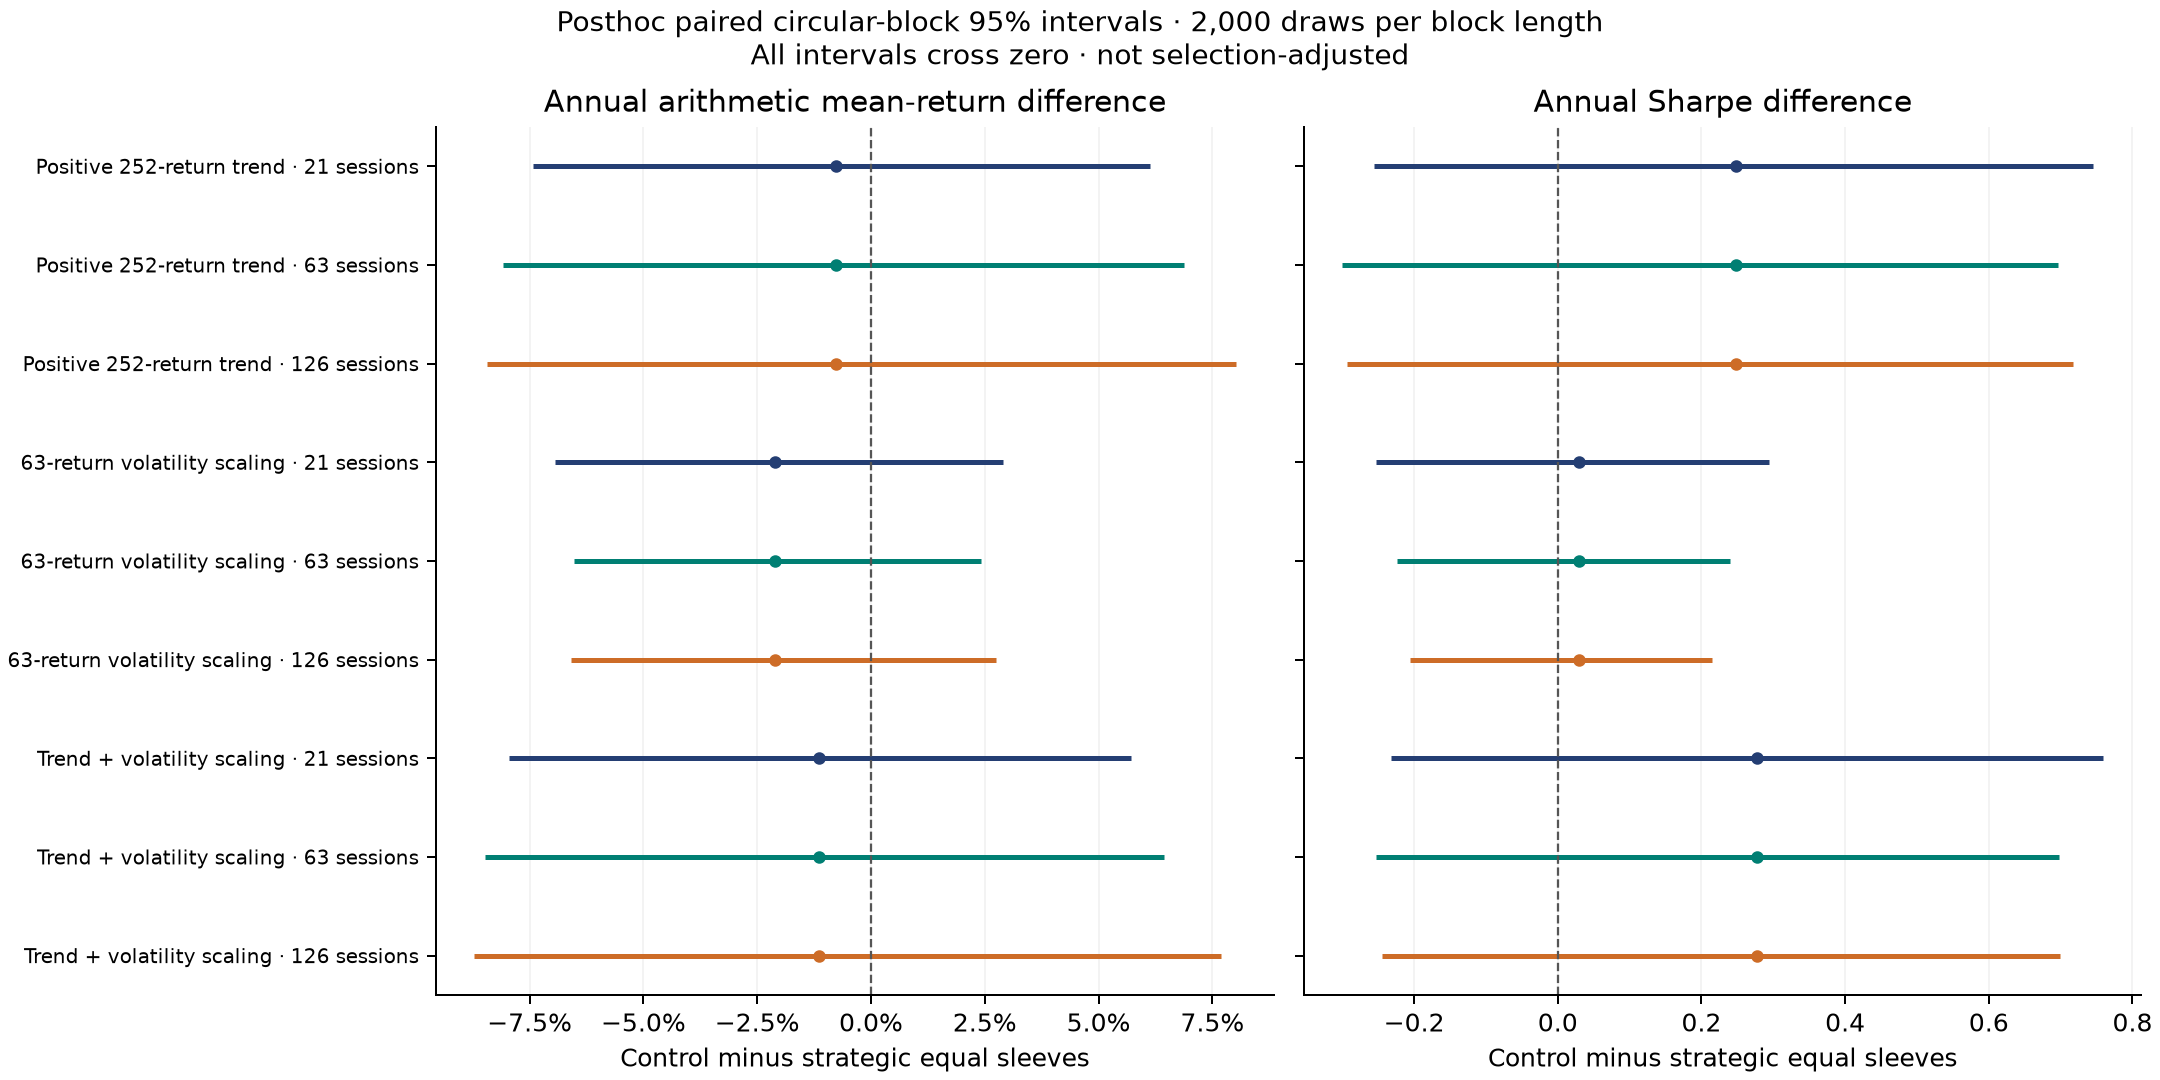

In [5]:
uncertainty = json.loads((report / 'uncertainty.json').read_text())
intervals = []
for policy, result in uncertainty['comparisons'].items():
    assert not result['selection_adjusted']
    for block in result['block_sensitivity']:
        lo, hi = block['annual_sharpe_difference_interval']
        assert lo <= 0 <= hi
        intervals.append(dict(policy=policy, block_sessions=block['block_sessions'],
            observed_Sharpe_difference=result['observed_annual_sharpe_difference'],
            lower_95=lo, upper_95=hi))
display(pd.DataFrame(intervals).set_index(['policy','block_sessions']).round(4))
display(Image(filename=str(report / 'uncertainty.png')))

## Trend and scaling components

Compare each switch with and without the other switch, plus the four-way interaction. Sharpe contrasts subtract the four separately calculated ratios; they are not the Sharpe of a return-difference series. Shared observed date blocks preserve the four-policy vector. These are post-hoc development intervals without an adjustment for strategy selection.

In [6]:
from datetime import date
from quantlab.evaluation.factorial import ARMS, component_intervals
assert sha(root/'src/quantlab/evaluation/factorial.py') == '324b51d2df6bcad2594c173c301dc2ddd815f4980ec7fdbc3f076c7bd93e064e'
component_returns = daily.pivot(index='session',columns='policy',
    values='daily_net_return').sort_index()
assert component_returns.shape == (1975,4)
inputs = {arm:component_returns[arm].to_numpy() for arm in ARMS}
component_rows = []
for block in (21,63,126):
    analysis = component_intervals([day.date() for day in component_returns.index],
        inputs,block_sessions=block)
    assert analysis['undefined_sharpe_draws'] == 0
    for contrast in analysis['contrasts']:
        lo,hi = contrast['annual_sharpe_95_interval']
        component_rows.append(dict(component=contrast['name'],block_sessions=block,
            Sharpe_difference=contrast['annual_sharpe_difference'],
            lower_95=lo,upper_95=hi))
display(pd.DataFrame(component_rows).set_index(['component','block_sessions']).round(4))

,,Sharpe_difference,lower_95,upper_95
component,block_sessions,,,
trend_without_scaler,21,0.2484,-0.2554,0.7452
scaler_without_trend,21,0.0302,-0.2536,0.2942
trend_with_scaler,21,0.2467,-0.0844,0.5939
scaler_with_trend,21,0.0285,-0.0762,0.1498
interaction,21,-0.0016,-0.2862,0.2869
trend_without_scaler,63,0.2484,-0.3003,0.6959
scaler_without_trend,63,0.0302,-0.2244,0.2393
trend_with_scaler,63,0.2467,-0.1464,0.5897
scaler_with_trend,63,0.0285,-0.0665,0.1385


## Reference drawdowns and missed rebounds

This descriptive rule enumerates every equal-weight reference drawdown of at least 10%, ending at its first recovery to the prior peak. It permits one active episode at a time and retains unrecovered episodes as censored. The rule was added after the development run; eventual troughs and recoveries are hindsight outcomes, not historical signals. Every policy is compared over identical reference dates.

,peak_session,peak_nav,threshold_crossing_session,trough_session,trough_nav,end_session,recovery_session,right_censored,episode_id,threshold,maximum_reference_drawdown,hindsight_outcome_only
0,2008-05-19,119357.982271,2008-09-04,2009-03-09,72482.524813,2010-09-24,2010-09-24,False,reference_drawdown_001,-0.1,-0.392730,True
1,2011-04-29,136847.013444,2011-10-03,2011-10-03,123160.830386,2012-01-25,2012-01-25,False,reference_drawdown_002,-0.1,-0.100011,True


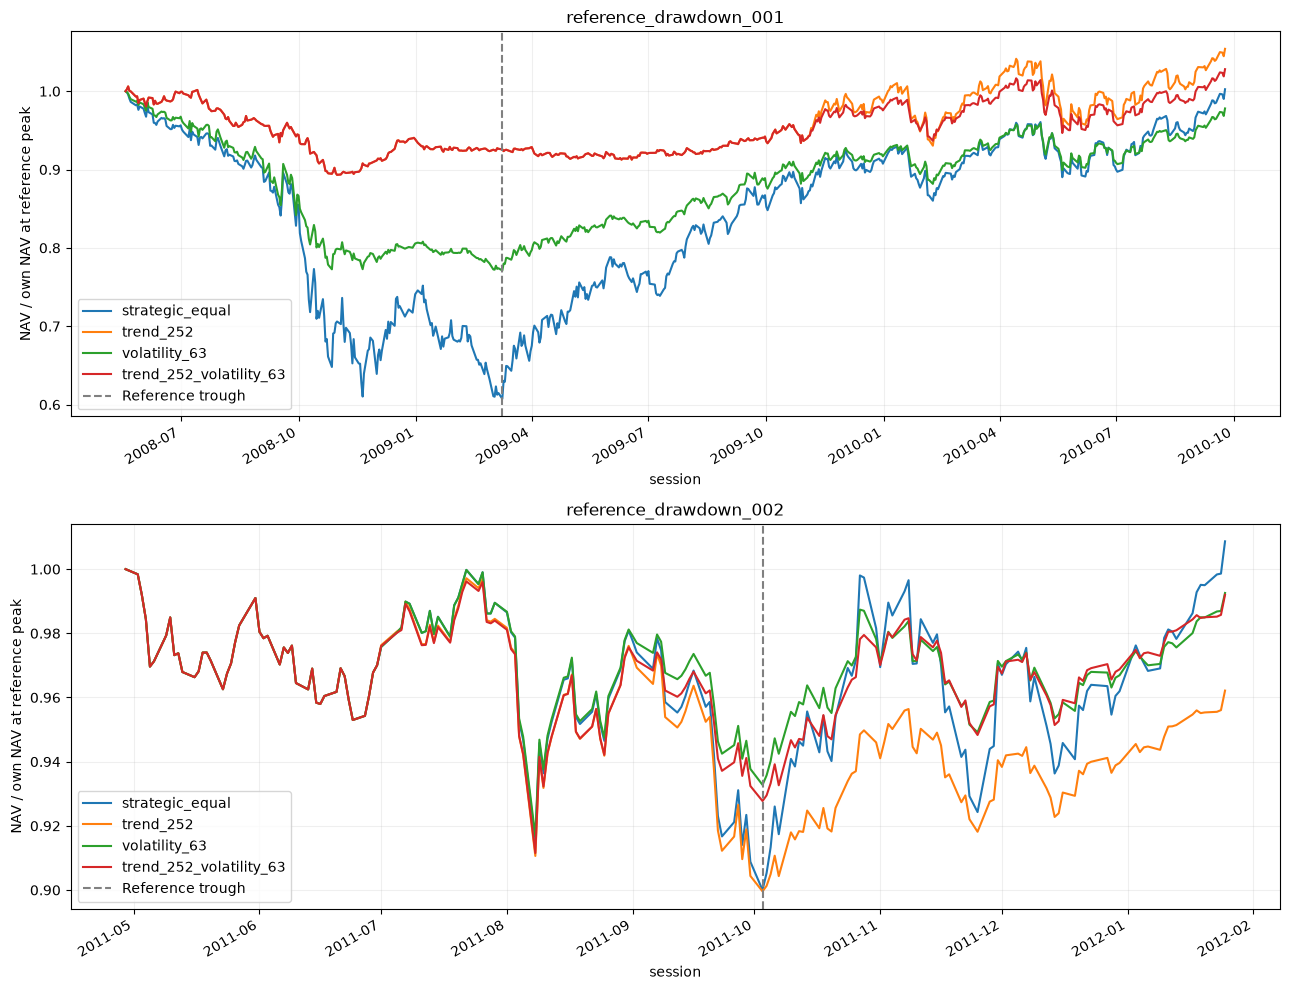

peak_to_reference_trough  \
episode                policy                                              
reference_drawdown_001 strategic_equal                           -0.3927   
                       trend_252                                 -0.0742   
                       volatility_63                             -0.2288   
                       trend_252_volatility_63                   -0.0742   
reference_drawdown_002 strategic_equal                           -0.1000   
                       trend_252                                 -0.1004   
                       volatility_63                             -0.0672   
                       trend_252_volatility_63                   -0.0723   

                                                reference_trough_to_end  \
episode                policy                                             
reference_drawdown_001 strategic_equal                           0.6509   
                       trend_252                                 0.1386   
                       volatility_63                             0.2682   
                       trend_252_volatility_63                   0.1106   
reference_drawdown_002 strategic_equal                           0.1208   
                       trend_252                                 0.0696   
                       volatility_63                             0.0641   
                       trend_252_volatility_63                   0.0693   

                                                mean_rebound_risky_weight  \
episode                policy                                               
reference_drawdown_001 strategic_equal                             1.0000   
                       trend_252                                   0.6539   
                       volatility_63                               0.6024   
                       trend_252_volatility_63                     0.5181   
reference_drawdown_002 strategic_equal                             1.0000   
                       trend_252                                   0.7266   
                       volatility_63                               0.5254   
                       trend_252_volatility_63                     0.7112   

                                                right_censored  
episode                policy                                   
reference_drawdown_001 strategic_equal                   False  
                       trend_252                         False  
                       volatility_63                     False  
                       trend_252_volatility_63           False  
reference_drawdown_002 strategic_equal                   False  
                       trend_252                         False  
                       volatility_63                     False  
                       trend_252_volatility_63           False

In [7]:
from datetime import date
from quantlab.evaluation.episodes import drawdown_episodes
import matplotlib.pyplot as plt
assert sha(root/'src/quantlab/evaluation/episodes.py') == '487d38cb62ce22cda26523ec76c0370bd9bcfaa5707c66dd2403f7a2ef24519b'
navs = daily.pivot(index='session',columns='policy',values='close_nav').sort_index()
exposures = daily.pivot(index='session',columns='policy',values='risky_weight')
assert navs.shape == (1975,4) and navs.notna().all().all()
episodes = drawdown_episodes([day.date() for day in navs.index],
    navs['strategic_equal'],initial_session=date(2007,2,28),initial_nav=100000)
display(pd.DataFrame(episodes))
comparisons = []
fig, axes = plt.subplots(len(episodes),1,figsize=(13,5*len(episodes)),squeeze=False)
for ax, episode in zip(axes[:,0],episodes,strict=True):
    peak,trough,end = [pd.Timestamp(episode[key]) for key in
                      ('peak_session','trough_session','end_session')]
    for policy in policies:
        start_nav = 100000 if peak == pd.Timestamp('2007-02-28') else navs.loc[peak,policy]
        comparisons.append(dict(episode=episode['episode_id'],policy=policy,
            peak_to_reference_trough=navs.loc[trough,policy]/start_nav-1,
            reference_trough_to_end=navs.loc[end,policy]/navs.loc[trough,policy]-1,
            mean_rebound_risky_weight=exposures.loc[trough:end,policy].mean(),
            right_censored=episode['right_censored']))
        (navs.loc[peak:end,policy]/start_nav).plot(ax=ax,label=policy)
    ax.axvline(trough,color='gray',linestyle='--',label='Reference trough')
    ax.set_title(episode['episode_id'])
    ax.set_ylabel('NAV / own NAV at reference peak')
    ax.legend(); ax.grid(alpha=.2)
fig.tight_layout(); plt.show()
display(pd.DataFrame(comparisons).set_index(['episode','policy']).round(4))

In the first reference episode, trend reduced the peak-to-trough loss, but captured much less of the subsequent recovery. In the second, trend alone did not reduce the loss. These are reference-window comparisons, not each policy's own maximum drawdown or evidence that an eventual trough could be identified in real time.

## Trading costs and owned asset P&L

The four policies were rerun on all 1,975 development sessions at 0, 5, 10 and 25 bp per traded side. Targets are identical across fee scenarios; fees are funded from each portfolio's own NAV. Independent accounting checks used saved holdings and observed opening/closing marks for all 31,600 daily records. These assumed fees are sensitivity scenarios, not observed auction costs.

fee_bps,0,5,10,25
policy,,,,
strategic_equal,0.4236,0.4219,0.4202,0.4152
trend_252,0.6845,0.6766,0.6686,0.6446
trend_252_volatility_63,0.7177,0.7074,0.6972,0.6662
volatility_63,0.4595,0.4550,0.4504,0.4367


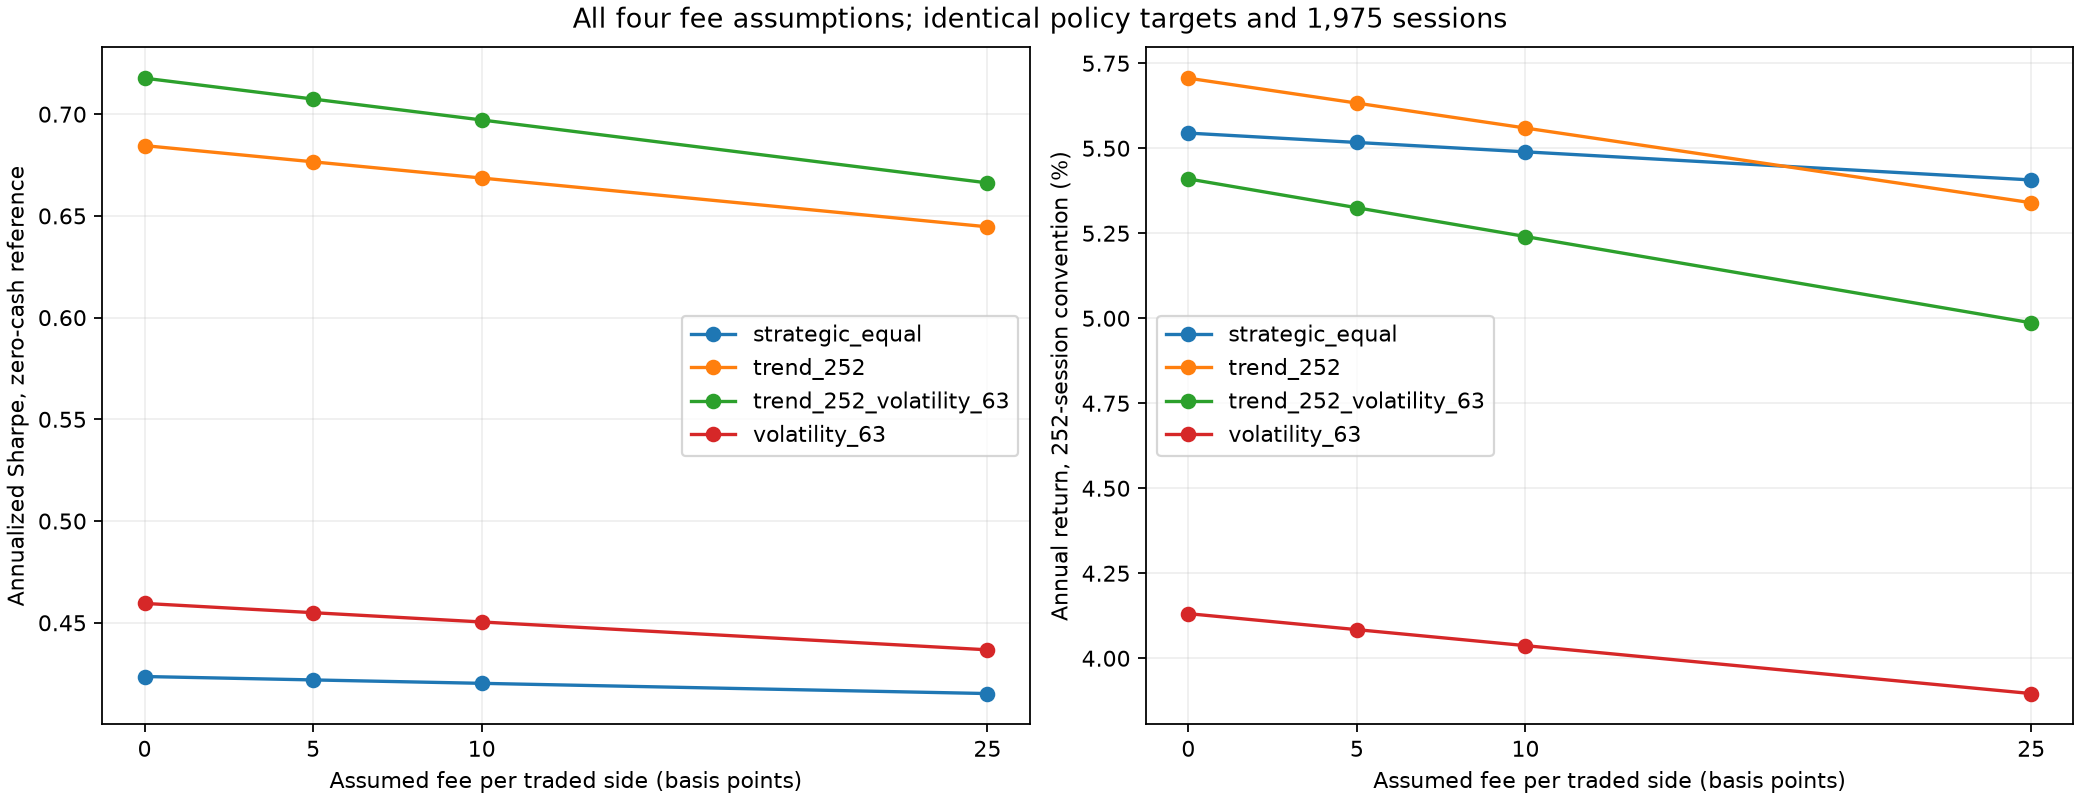

component,cash,etf:dbc.us,etf:eem.us,etf:efa.us,etf:gld.us,etf:lqd.us,etf:spy.us,etf:tlt.us,etf:vnq.us,fees
policy,,,,,,,,,,
strategic_equal,0.0,-2835.30,4648.21,2825.19,7557.60,6801.69,11136.76,11066.25,11280.60,-463.21
trend_252,0.0,162.23,-378.06,2457.62,11162.85,4574.25,13824.62,9478.09,12884.49,-1355.95
trend_252_volatility_63,0.0,747.42,183.67,2918.93,9967.65,3892.25,13542.88,7609.42,11890.78,-1526.01
volatility_63,0.0,-2844.98,1973.37,1632.55,4260.71,3847.68,9361.42,8732.17,10192.06,-788.16


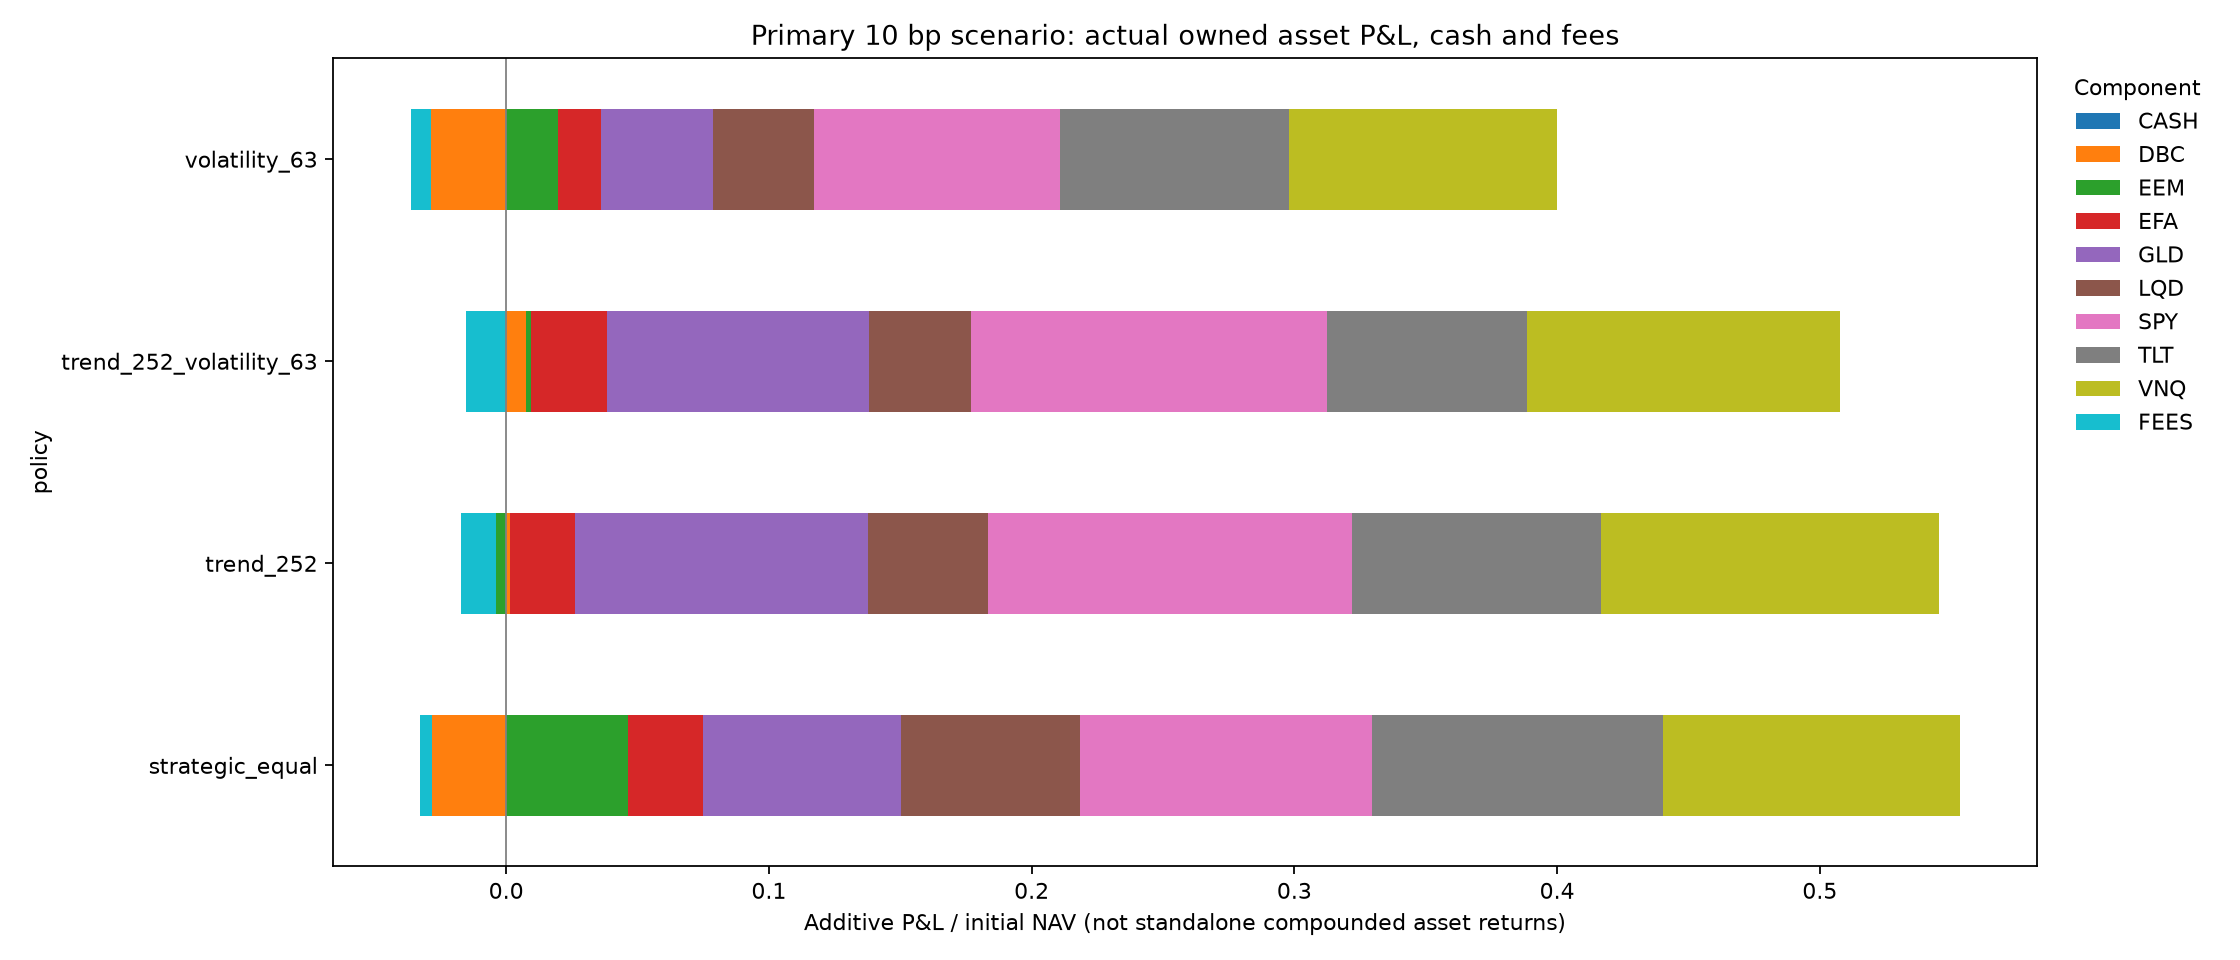

In [8]:
cost_report = root/'reports/etf_cost_sensitivity_v2'
cost_manifest = json.loads((cost_report/'export_manifest.json').read_text())
assert (cost_report/'COMPLETE').read_text().strip() == sha(cost_report/'export_manifest.json')
assert cost_manifest['paths']==16 and cost_manifest['sessions_per_path']==1975
assert not cost_manifest['holdout_evaluated']
for name,digest in cost_manifest['outputs_sha256'].items():
    assert sha(cost_report/name)==digest,name
costs = pd.read_csv(cost_report/'metrics.csv',float_precision='round_trip')
assert len(costs)==16 and costs.measured_sessions.eq(1975).all()
display(costs.pivot(index='policy',columns='fee_bps',
    values='annual_sharpe_zero_cash_reference').round(4))
display(Image(filename=str(cost_report/'cost_sensitivity.png')))
owned = pd.read_csv(cost_report/'monetary_contributions.csv',
    float_precision='round_trip')
totals = owned.groupby(['fee_bps','policy']).money_pnl.sum()
for row in costs.itertuples():
    assert np.isclose(totals.loc[row.fee_bps,row.policy]/100000,
        row.net_return,rtol=0,atol=1e-10)
display(owned[owned.fee_bps==10].pivot(index='policy',columns='component',
    values='money_pnl').round(2))
display(Image(filename=str(cost_report/'monetary_attribution.png')))

The combined policy's observed Sharpe falls from about 0.718 with zero fees to 0.666 at 25 bp. Its annual return remains below equal sleeves, despite its higher observed Sharpe. Asset contributions sum in money and initial-NAV units; they are not separately compounded asset-return contributions. No fee scenario is selected as a winning recipe.

## Requested and realized volatility

The 10% rule scales exposure down and never adds leverage. It cannot guarantee 10% realized risk. These saved 10 bp policy trajectories cover 94 complete signal intervals and all 1,975 sessions for each control. Realized volatility includes actual changing holdings and fees; this is a policy diagnostic, not a fixed-portfolio variance forecast test.

,months,sessions,median_monthly_annual_volatility,mean_monthly_annual_volatility,fraction_months_over_requested_10pct,mean_intended_cash,fraction_unscaled
policy,,,,,,,
strategic_equal,94,1975,0.099609,0.128835,0.489362,0.000000,1.000000
trend_252,94,1975,0.063675,0.075811,0.244681,0.287234,1.000000
trend_252_volatility_63,94,1975,0.061121,0.069381,0.170213,0.335873,0.723404
volatility_63,94,1975,0.080913,0.089814,0.287234,0.191409,0.393617


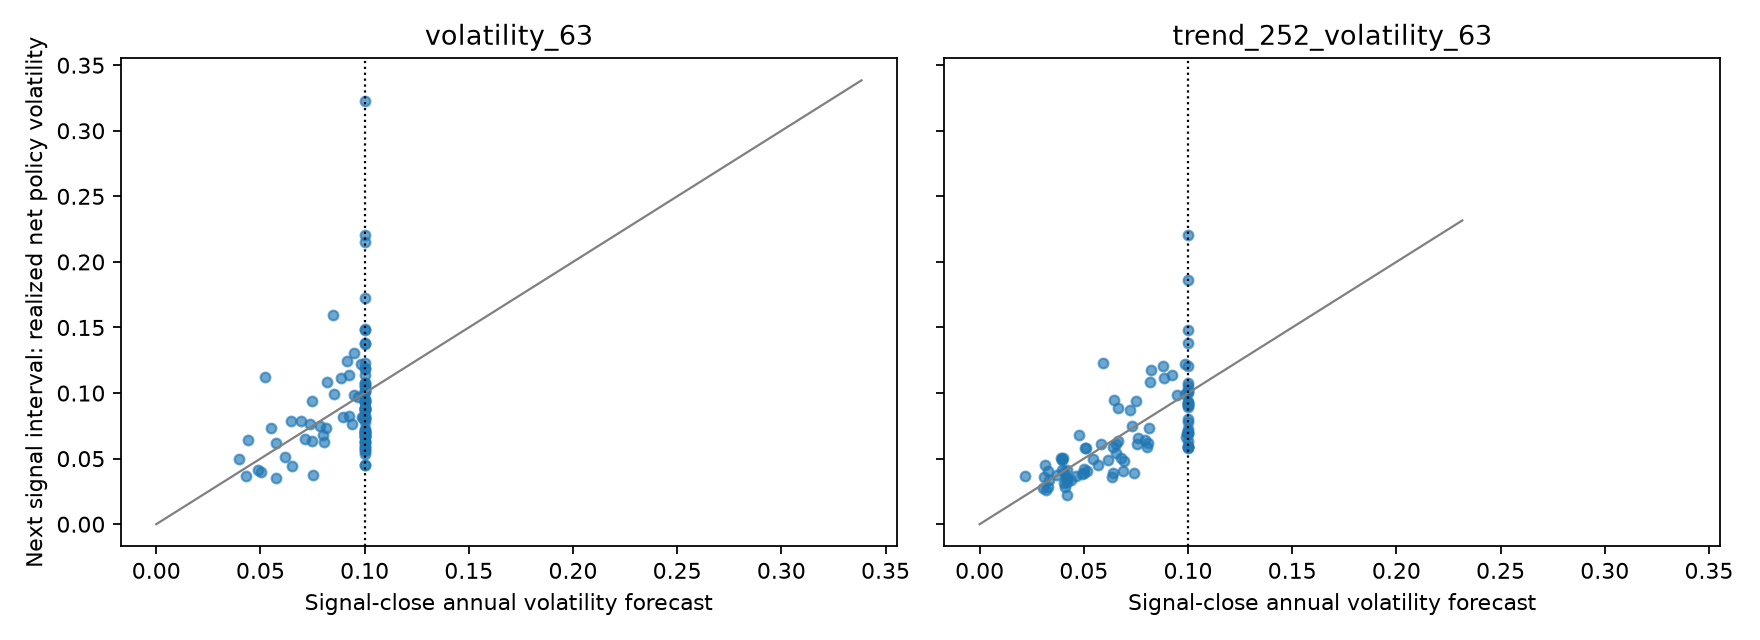

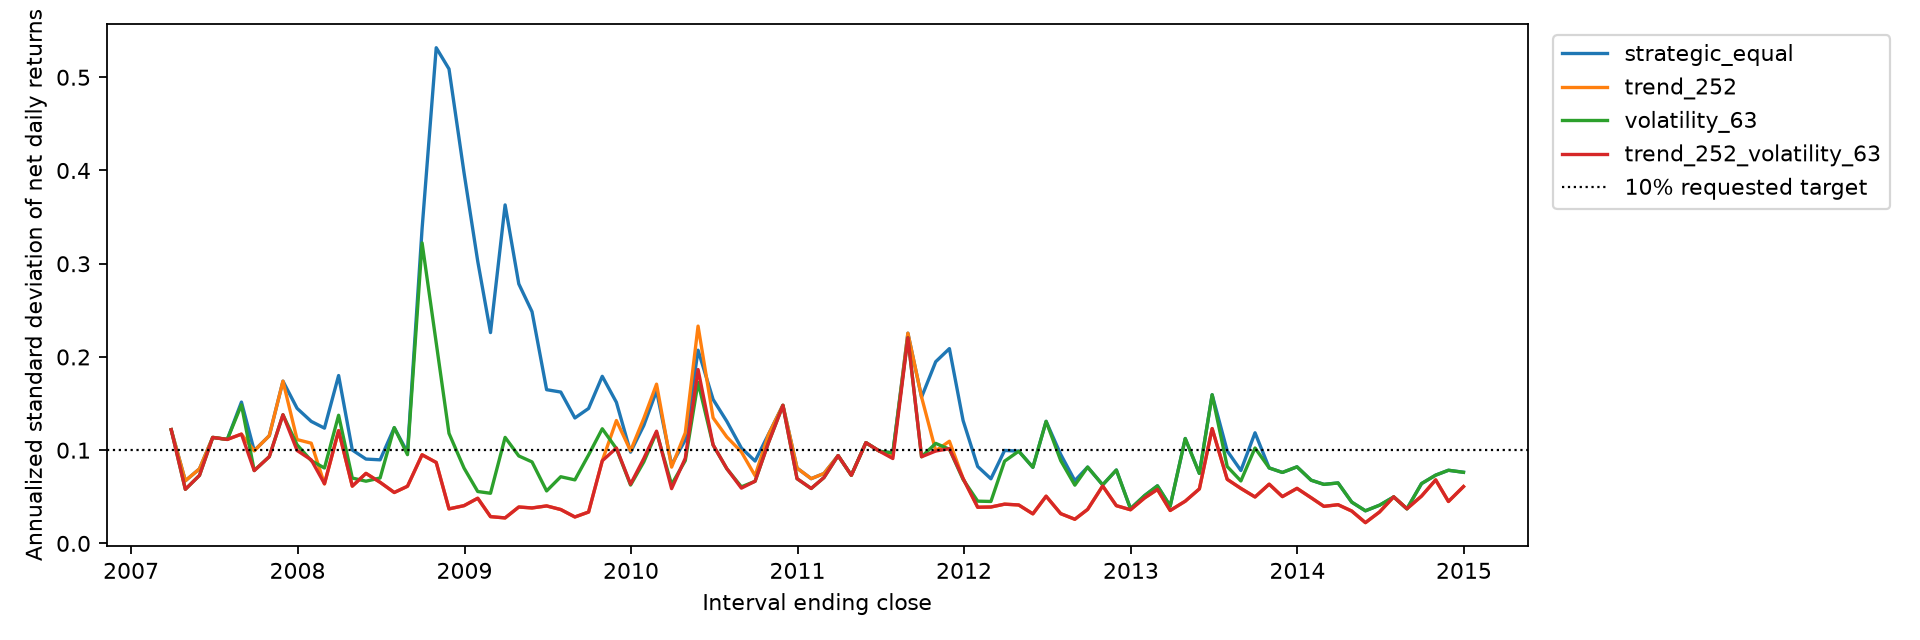

In [9]:
calibration = root/'reports/etf_target_calibration_v1'
calibration_manifest = json.loads((calibration/'export-manifest.json').read_text())
assert (calibration/'COMPLETE').read_text().strip() == sha(calibration/'export-manifest.json')
for name,digest in calibration_manifest['outputs_sha256'].items():
    assert sha(calibration/name)==digest,name
monthly_risk = pd.read_csv(calibration/'monthly_policy_risk.csv')
assert len(monthly_risk)==376
assert monthly_risk.groupby('policy').sessions.sum().eq(1975).all()
all_targets = pd.read_csv(calibration/'signal_targets.csv')
assert len(all_targets)==380 and (~all_targets.executed_in_window).sum()==4
display(pd.read_csv(calibration/'summary.csv').set_index('policy'))
display(Image(filename=str(calibration/'forecast_vs_policy_risk.png')))
display(Image(filename=str(calibration/'monthly_realized_policy_risk.png')))

The combined rule exceeds 10% annualized volatility in 16 of 94 monthly intervals. Its average intended cash weight is about 33.6%. The final December 2014 target remains pending and has no January 2015 outcome here. The identity line is a visual reference, not a claim that the signal-close forecast and changing net portfolio trajectory have identical targets.

## What the completed study supports

The combined control has the highest **observed** Sharpe (about 0.697 versus 0.420 for strategic equal sleeves) and lower close drawdown (about 11.2% versus 39.3%). Its cumulative net return is lower (49.2% versus 52.0%). Trend alone has a slightly higher cumulative return (52.8%), with lower risk and less invested exposure than strategic equal sleeves. These differences describe the same complete period and fixed accounting rules.

The combined control's Sharpe difference is about +0.277, but its 63-session-block 95% interval is roughly **[-0.254, +0.698]**. All other reported block choices and control pairs also span zero. The evidence does not establish statistically reliable superiority. Lower exposure and the observed crisis path help explain the drawdown comparison; they do not identify a universally better allocation.

This is a fixed development control study, conditional on a current-vintage adjusted-price proxy and an explicit execution-cost model. There is no 2015+ strategy score, final winner freeze, slippage/spread/impact study, tax analysis, explicit distribution settlement, or point-in-time publication-vintage proof. Later risk integration must first freeze a controlled economic protocol, then use the shared ledger and paired support; forecast losses alone are not portfolio performance.